# Fashion-MNIST classification with an MLP (PyTorch)

Goal: classify 28x28 grayscale images of clothes into **10 classes** with a Multi-Layer Perceptron built from scratch in PyTorch.

Steps of this notebook:
1. Load the data and compute the normalization values myself
2. Build the MLP (Linear + BatchNorm + ReLU + Dropout)
3. Write the training and validation loops
4. Analyse the results: learning curves, probabilities, confusion matrix

In [2]:
# torchinfo prints a summary of the model (layers, output shapes, parameters)
!pip install -q torchinfo

In [3]:
# PyTorch: tensors, layers, loss functions and optimizers
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchinfo import summary
# torchvision gives the FashionMNIST dataset and image transforms
import torchvision
from torchvision import datasets,transforms
# Tools for plots and numbers
import matplotlib.pyplot as plt
import  numpy as np
import random
import time
import pandas as pd
%matplotlib inline


In [4]:
# Use the same random seed everywhere, so I can run the notebook again
# and get (almost) the same results.
def set_seeds():
    # set random seed value
    SEED_VALUE = 42

    random.seed(SEED_VALUE)
    np.random.seed(SEED_VALUE)
    torch.manual_seed(SEED_VALUE)
    # Fix seed to make training deterministic.
    if torch.cuda.is_available():
       torch.cuda.manual_seed(SEED_VALUE)
       torch.cuda.manual_seed_all(SEED_VALUE)
       torch.backends.cudnn.deterministic = True
       torch.backends.cudnn.benchmark = True
set_seeds()

## 1. Data: loading and normalization

In [5]:
# Step 1: load the training images WITHOUT normalization.
# ToTensor() changes each image to a tensor of shape (1, 28, 28) with values between 0 and 1.
# I need these raw values to calculate the mean and the standard deviation myself.
raw_transform = transforms.Compose([transforms.ToTensor()])

train_set_raw = datasets.FashionMNIST(root="F_MNIST_data",download=True,train=True,transform=raw_transform)



100%|██████████| 26.4M/26.4M [00:01<00:00, 13.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.2MB/s]


In [6]:
# Step 2: put all pixels of the 60,000 training images in one long vector
# and calculate their mean and standard deviation (std).
all_pixels = torch.cat([img.view(-1) for img , _ in train_set_raw])
mean = all_pixels.mean().item()
std = all_pixels.std().item()
print(f"{mean:.4f}")
print(f"{std:.4f}")

# Step 3: normalize every image with (pixel - mean) / std.
# With centered values (mean around 0, std around 1), training is faster and more stable.
# I use only the TRAINING statistics, also for the validation set, so no information comes from the test data.
transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize((mean,),(std,))])

# train=True -> 60,000 training images, train=False -> 10,000 test images (used here as validation set)
train_set =datasets.FashionMNIST(root="F_MNIST_data",download=True,train=True,transform=transform)
val_set =  datasets.FashionMNIST(root="F_MNIST_data",download=True,train=False,transform=transform)
print(len(train_set),len(val_set))

0.2860
0.3530
60000 10000


In [7]:
# DataLoader gives the data in mini-batches of 64 images.
# shuffle=True for training: a new random order at every epoch helps the model to generalize.
# shuffle=False for validation: the order does not change the result.
train_loader = torch.utils.data.DataLoader(train_set,shuffle = True, batch_size = 64)
val_loader = torch.utils.data.DataLoader(val_set,shuffle = False, batch_size = 64)

In [8]:
# The dataset gives only numbers (0-9) as labels. This dictionary gives the name of each class.
class_mapping = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}

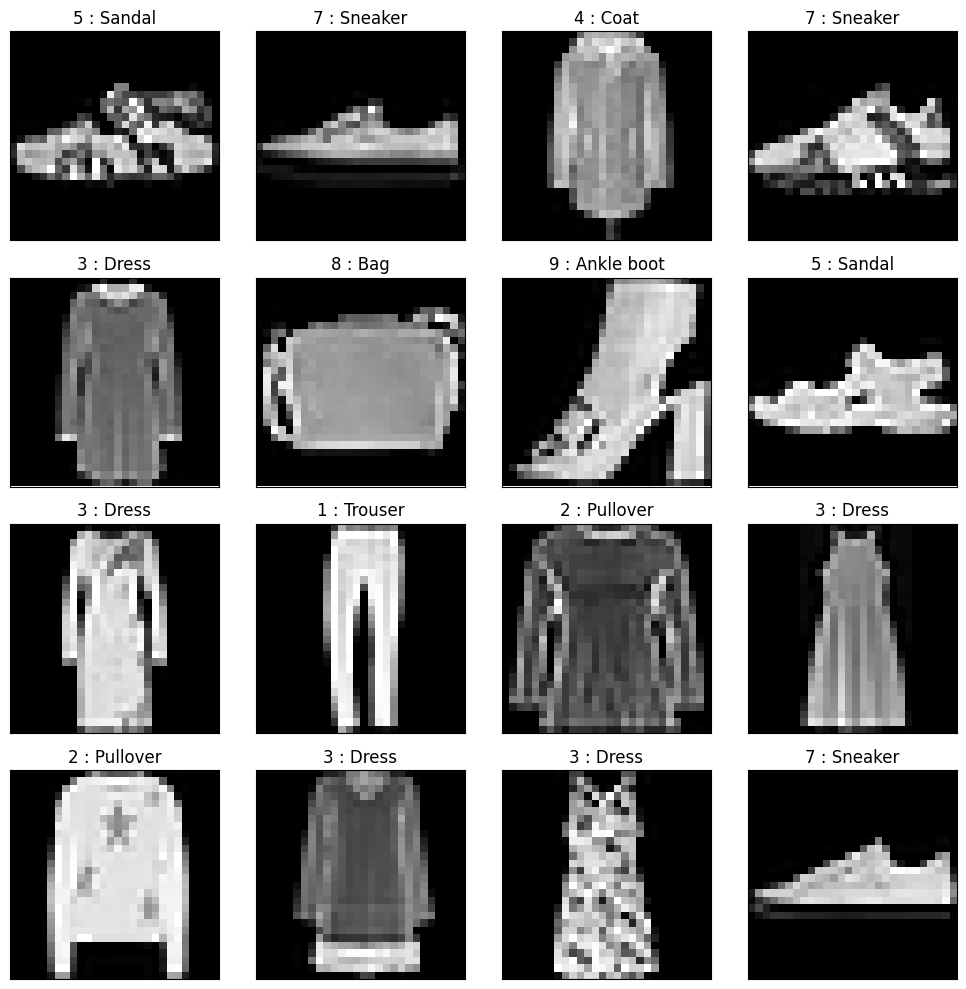

In [9]:
# Show some images of one batch with their labels, to check that the data is correct.
def visualize_images(trainloader, num_imgs = 20):
    fig = plt.figure(figsize=(10,10))
    images,labels = next(iter(trainloader))
    
    numRows = 4
    numCols = int((np.ceil(num_imgs/numRows)))
    
    for idx in range(min(num_imgs, len(images))):
        image,label = images[idx] , labels[idx]
        ax = fig.add_subplot(numRows, numCols,idx+1,xticks = [],yticks = [])
        ax.imshow(np.squeeze(image),cmap="gray")
        ax.set_title(f"{label.item()} : {class_mapping[label.item()]}")
    fig.tight_layout()
    plt.show()
    
    
visualize_images(train_loader,num_imgs=16)

## 2. Model: Multi-Layer Perceptron

In [10]:
# Multi-Layer Perceptron (MLP): only fully connected layers, no convolution.
# Sizes: 784 -> 512 -> 256 -> 128 -> 64 -> 10
class MLP(nn.Module):
    def __init__(self,num_class):
        super().__init__()
        # Each hidden block = Linear layer + BatchNorm.
        # BatchNorm1d normalizes the outputs of a layer for each batch: training is more stable
        # and I can use a bigger learning rate.
        self.fc0 = nn.Linear(784,512)
        self.bn0 = nn.BatchNorm1d(512)
        self.fc1 = nn.Linear(512,256)
        self.bn1 = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256,128)
        self.bn2 = nn.BatchNorm1d(128)
        self.fc3 = nn.Linear(128,64)
        self.bn3 = nn.BatchNorm1d(64)
        # Last layer: one score (logit) for each of the 10 classes
        self.fc4 = nn.Linear(64,num_class)
        
        # Dropout turns off 30% of the neurons at random during training.
        # The model cannot depend on only a few neurons, so it overfits less.
        self.dropout = nn.Dropout(p=0.3)
    def forward(self,x):
        # Flatten: (batch, 1, 28, 28) -> (batch, 784), because a Linear layer needs a vector
        x = x.view(x.shape[0],-1)
        # Linear -> BatchNorm -> ReLU. ReLU adds non-linearity: without it, all the layers
        # together would be the same as only one linear layer.
        x = F.relu(self.bn0(self.fc0(x)))
        x = self.dropout(x)
        x = F.relu(self.bn1(self.fc1(x)))
        x = F.relu(self.bn2(self.fc2(x)))
        x = self.dropout(x)
        x = F.relu(self.bn3(self.fc3(x)))
        # log_softmax gives log-probabilities. It works together with nll_loss:
        # log_softmax + nll_loss = cross-entropy loss.
        x = F.log_softmax(self.fc4(x),dim=1)
        
        return x


mlp_model = MLP(num_class=10)        
        

In [11]:
# Check the shape of each layer and the number of parameters (576,970 in total).
# Example: fc0 has 784 * 512 weights + 512 biases = 401,920 parameters.
print(summary(mlp_model, input_size = (64,1,28,28), row_settings = ["var_names"]))

Layer (type (var_name))                  Output Shape              Param #
MLP (MLP)                                [64, 10]                  --
├─Linear (fc0)                           [64, 512]                 401,920
├─BatchNorm1d (bn0)                      [64, 512]                 1,024
├─Dropout (dropout)                      [64, 512]                 --
├─Linear (fc1)                           [64, 256]                 131,328
├─BatchNorm1d (bn1)                      [64, 256]                 512
├─Linear (fc2)                           [64, 128]                 32,896
├─BatchNorm1d (bn2)                      [64, 128]                 256
├─Dropout (dropout)                      [64, 128]                 --
├─Linear (fc3)                           [64, 64]                  8,256
├─BatchNorm1d (bn3)                      [64, 64]                  128
├─Linear (fc4)                           [64, 10]                  650
Total params: 576,970
Trainable params: 576,970
Non-trainable

## 3. Training

In [12]:
# Negative log-likelihood loss (the model already returns log-probabilities)
criterion = F.nll_loss
# Adam changes the learning step for each parameter. Learning rate = 0.01
optimizer = optim.Adam(mlp_model.parameters(),lr=1e-2)
num_epochs = 40
# Use the GPU if there is one, otherwise the CPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [13]:
# One training epoch = the model sees every training image one time.
def train(model,trainloader , criterion , optimizer , DEVICE):
    # Training mode: Dropout is active and BatchNorm uses the statistics of the current batch
    model.train()
    model.to(DEVICE)
    runnig_los = 0
    correct_predition = 0
    total_samples = 0
    for images,labels in trainloader:
        images,labels = images.to(DEVICE), labels.to(DEVICE)
        # 1. Set the old gradients to zero (PyTorch adds new gradients to the old ones)
        optimizer.zero_grad()
        # 2. Forward pass: compute the predictions
        outputs = model(images)
        # 3. Compute the loss: how far the predictions are from the true labels
        loss = criterion(outputs,labels)
        # 4. Backpropagation: compute the gradient of the loss for every weight (chain rule)
        loss.backward()
        # 5. Update the weights in the direction that makes the loss smaller
        optimizer.step()
        runnig_los += loss.item()
        # The predicted class is the class with the highest score
        _,predicted = torch.max(outputs.data,dim=1)
        total_samples += labels.size(0)
        correct_predition += (predicted==labels).sum().item()
    avg_loss = runnig_los/len(trainloader)
    accuracy = 100* (correct_predition/total_samples)  
    return avg_loss,accuracy
    
    

In [14]:
# Evaluate the model on images it never saw during training.
def validation(model , valLoader , criterion ,DEVICE):
    # Evaluation mode: Dropout is off and BatchNorm uses the statistics learned during training
    model.eval()
    model.to(DEVICE)
    runnig_loss = 0
    correct_predition = 0
    total_samples = 0
    # No gradients here: we do not train, so this saves memory and time
    with torch.no_grad():
        for images , labels in valLoader:
            images , labels = images.to(DEVICE) , labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            runnig_loss += loss.item()
            _,predicted = torch.max(outputs.data,dim = 1)
            total_samples += labels.size(0)
            correct_predition += (predicted==labels).sum().item()
    avg_loss = runnig_loss/len(valLoader)
    accuracy  = 100*(correct_predition/total_samples)
    return avg_loss , accuracy
            

In [15]:
# Train for several epochs. After each epoch, save the loss and the accuracy
# for train and validation, then draw the learning curves.
def main(model , trainLoader , valLoader,epochs = 5 ,DEVICE = "cuda"):
    trainLosses , valLosses = [],[]
    trainAccracies , valAccracies = [],[]
    
    
    for epoch in range(epochs):
        trainLoss , trainAcc = train(model , trainLoader , criterion, optimizer,DEVICE)
        valLoss , valAcc = validation(model , valLoader,criterion,DEVICE)
        trainLosses.append(trainLoss)
        trainAccracies.append(trainAcc)
        valLosses.append(valLoss)
        valAccracies.append(valAcc)
        print(f"Epoch {epoch+1:0>2}/{epochs} - Train Loss: {trainLoss :.4f}, Train Accuracy: {trainAcc:.2f}% - Val Loss: {valLoss:.4f}, Val Accuracy: {valAcc:.2f}%")
    
    
    # If the train loss goes down but the validation loss stays flat, the model starts to overfit.
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(range(1, epochs + 1), trainLosses, label='Train Loss')
    plt.plot(range(1, epochs + 1), valLosses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(range(1, epochs + 1), trainAccracies, label='Train Accuracy')
    plt.plot(range(1, epochs + 1), valAccracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()
         
    

Epoch 01/40 - Train Loss: 0.5594, Train Accuracy: 80.14% - Val Loss: 0.4213, Val Accuracy: 84.82%
Epoch 02/40 - Train Loss: 0.4387, Train Accuracy: 84.24% - Val Loss: 0.4086, Val Accuracy: 84.86%
Epoch 03/40 - Train Loss: 0.4009, Train Accuracy: 85.56% - Val Loss: 0.3896, Val Accuracy: 86.11%
Epoch 04/40 - Train Loss: 0.3724, Train Accuracy: 86.63% - Val Loss: 0.3638, Val Accuracy: 86.67%
Epoch 05/40 - Train Loss: 0.3570, Train Accuracy: 87.16% - Val Loss: 0.3424, Val Accuracy: 87.64%
Epoch 06/40 - Train Loss: 0.3392, Train Accuracy: 87.76% - Val Loss: 0.3413, Val Accuracy: 87.79%
Epoch 07/40 - Train Loss: 0.3243, Train Accuracy: 88.15% - Val Loss: 0.3310, Val Accuracy: 88.04%
Epoch 08/40 - Train Loss: 0.3124, Train Accuracy: 88.51% - Val Loss: 0.3252, Val Accuracy: 87.61%
Epoch 09/40 - Train Loss: 0.3022, Train Accuracy: 89.05% - Val Loss: 0.3142, Val Accuracy: 88.73%
Epoch 10/40 - Train Loss: 0.2935, Train Accuracy: 89.37% - Val Loss: 0.3216, Val Accuracy: 88.01%
Epoch 11/40 - Train 

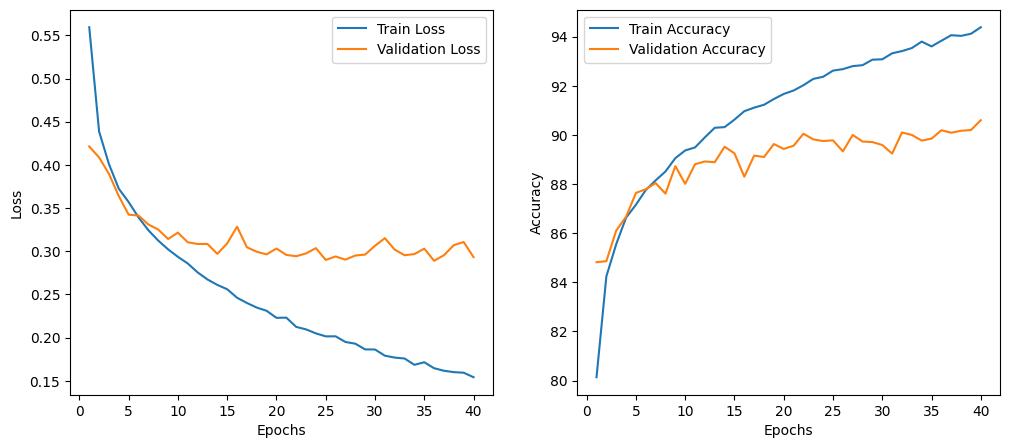

In [16]:
# Result after 40 epochs: train accuracy 94.38%, validation accuracy 90.60%.
# The gap between the two curves shows a small overfitting.
main(mlp_model, train_loader, val_loader,epochs=num_epochs,DEVICE=DEVICE)

## 4. Results and error analysis

64


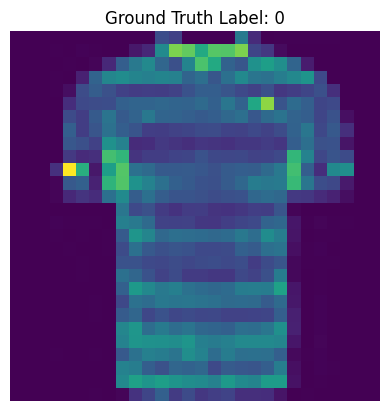

In [22]:
# Take one batch of validation images and show one random image with its true label.
images, gt_labels = next(iter(val_loader))
print(len(images))
rand_idx = random.choice(range(len(images)))

plt.imshow(images[rand_idx].squeeze())
plt.title("Ground Truth Label: " + str(int(gt_labels[rand_idx])), fontsize = 12)
plt.axis("off")
plt.show()

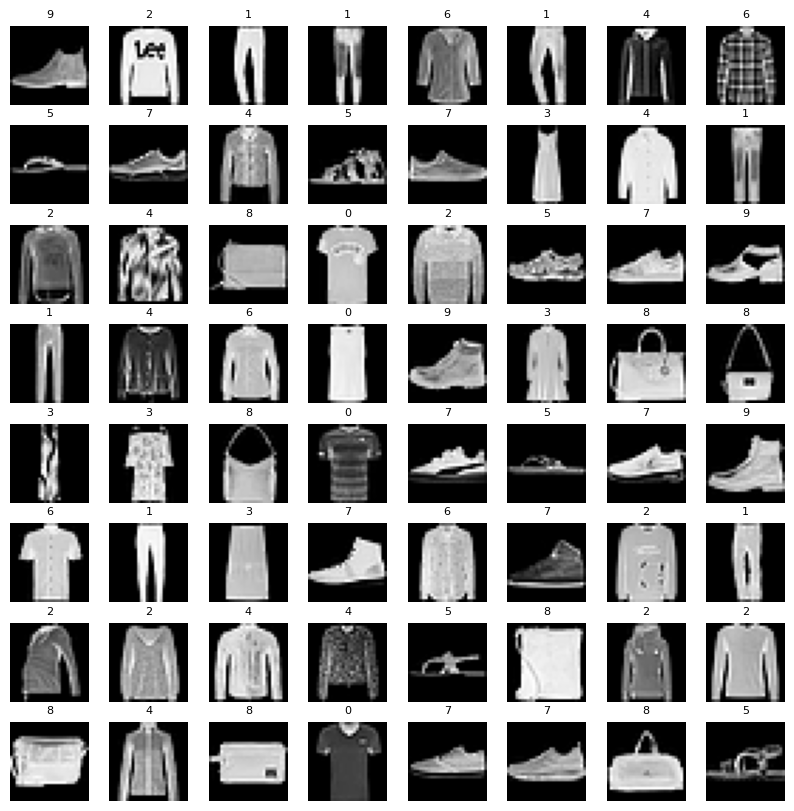

In [ ]:
# Show the full batch (64 images) in a grid with their true labels.
cols = 8
rows = (len(images) + cols - 1) // cols


fig, axes = plt.subplots(rows, cols, figsize=(cols, rows), squeeze=False)

for idx, ax in enumerate(axes.flat):
    ax.axis("off")
    if idx < len(images):
        ax.imshow(images[idx].squeeze(), cmap="gray")
        ax.set_title(str(gt_labels[idx].item()), fontsize=8)

plt.tight_layout(pad=0.3)
plt.show()

In [ ]:
# ANSI codes to print the predicted class in bold in the output
bold = "\033[1m"
reset = "\033[0m"

# For each image of the batch, show the probability of each class.
# softmax changes the scores into probabilities (the sum is 1).

mlp_model.eval()

with torch.no_grad():
    batch_outputs = mlp_model(images.to(DEVICE))
    prob_score_batch = batch_outputs.softmax(dim=1).cpu()

for img_idx, (prob_score_img, lbl) in enumerate(zip(prob_score_batch, gt_labels)):
    true_cls_id = lbl.item()
    pred_cls_id = prob_score_img.argmax().item()

    print(f"Image {img_idx + 1} | Ground truth: {class_mapping[true_cls_id]}")

    for cls_id, cls_prob in enumerate(prob_score_img):
        line = f"Class: {cls_id} - {class_mapping[cls_id]}, Probability: {cls_prob.item():.3f}"
        if cls_id == pred_cls_id:
            line = f"{bold}{line}{reset}"
        print(line)

    print("================================")

Image 1 | Ground truth: Ankle boot
Class: 0 - T-shirt/top, Probability: 0.000
Class: 1 - Trouser, Probability: 0.000
Class: 2 - Pullover, Probability: 0.000
Class: 3 - Dress, Probability: 0.000
Class: 4 - Coat, Probability: 0.000
Class: 5 - Sandal, Probability: 0.000
Class: 6 - Shirt, Probability: 0.000
Class: 7 - Sneaker, Probability: 0.000
Class: 8 - Bag, Probability: 0.000
Class: 9 - Ankle boot, Probability: 1.000
Image 2 | Ground truth: Pullover
Class: 0 - T-shirt/top, Probability: 0.000
Class: 1 - Trouser, Probability: 0.000
Class: 2 - Pullover, Probability: 1.000
Class: 3 - Dress, Probability: 0.000
Class: 4 - Coat, Probability: 0.000
Class: 5 - Sandal, Probability: 0.000
Class: 6 - Shirt, Probability: 0.000
Class: 7 - Sneaker, Probability: 0.000
Class: 8 - Bag, Probability: 0.000
Class: 9 - Ankle boot, Probability: 0.000
Image 3 | Ground truth: Trouser
Class: 0 - T-shirt/top, Probability: 0.000
Class: 1 - Trouser, Probability: 1.000
Class: 2 - Pullover, Probability: 0.000
Class:

In [30]:
# Tools for the confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sn

In [31]:
# Return the predicted class id for each image of a batch.
def prediction_batch(model, batch_inputs):
    model.eval()

    batch_outputs = model(batch_inputs)

    with torch.no_grad():
        batch_probs = batch_outputs.softmax(dim=1) #along num of classes dimension


    batch_cls_ids = batch_probs.argmax(dim=1)

    return batch_cls_ids.cpu()

In [32]:
# Predict the class of all 10,000 validation images and keep the true labels.
val_target_labels = []
val_predicted_labels = []

for image_batch, target_batch in val_loader:
    image_batch = image_batch.to(DEVICE)

    batch_pred_cls_id = prediction_batch(mlp_model, image_batch)

    val_predicted_labels.append(batch_pred_cls_id)
    val_target_labels.append(target_batch)

val_target_labels = torch.cat(val_target_labels).numpy()
val_predicted_labels = torch.cat(val_predicted_labels).numpy()

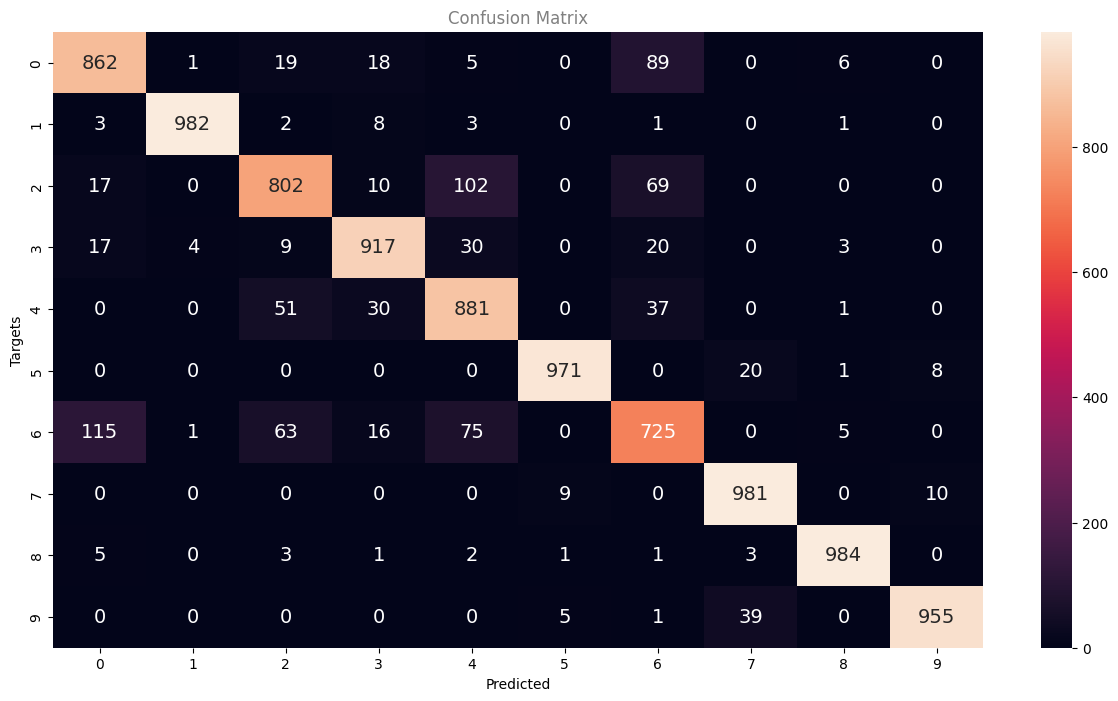

In [33]:
# Confusion matrix: row = true class, column = predicted class.
# The diagonal shows the correct predictions; the other cells show the mistakes.
cm = confusion_matrix(y_true=val_target_labels, y_pred = val_predicted_labels)

plt.figure(figsize= [15,8])

# Plot the confusion matrix as a heatmap.
sn.heatmap(cm, annot=True, fmt='d', annot_kws={"size":14})
plt.xlabel("Predicted")
plt.ylabel("Targets")
plt.title(f"Confusion Matrix", color="gray")
plt.show()

## 5. What I learned

- Validation accuracy: **90.60%** after 40 epochs (train accuracy: 94.38%).
- The hardest class is **Shirt** (725 / 1000 correct): it is often confused with T-shirt/top (115), Coat (75) and Pullover (63), because these clothes have a similar shape.
- After about 10 epochs the validation loss stays around 0.30 while the train loss still goes down (0.15 at the end): this is overfitting. Dropout and BatchNorm reduce it, but do not remove it.
- An MLP flattens the image, so it loses the 2D position of the pixels. A CNN should give better results on this task.